# Avance de Proyecto 2 - Desarrollo de aplicaciones con Inteligencia Artificial

Modelo de texto con TF-IDF + Naive Bayes y componente visual preparado con ResNet50.

**Nota:** El CSV contiene ejemplos de prueba. La CNN requiere imágenes oftalmológicas autorizadas y clasificadas. No se generan métricas sin datos reales.

In [1]:
!pip -q install nltk scikit-learn seaborn tensorflow

In [2]:
import re, unicodedata, random, os, csv, json
import numpy as np
import pandas as pd
import nltk
from nltk.tokenize import wordpunct_tokenize
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
import matplotlib.pyplot as plt

nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

## 1. Descripción del proyecto

- **Problema:** preguntas frecuentes y solicitudes de citas generan carga administrativa.
- **Objetivo:** responder consultas e identificar intenciones.
- **Usuarios:** pacientes y personal de la clínica.
- **Alcance:** orientación y solicitudes simuladas; sin agenda ni expedientes reales.
- **Flujo:** mensaje → preprocesamiento → clasificador → respuesta. Imagen → ResNet50 → clase y confianza.
- **Seguridad:** no diagnostica. Ante síntomas repentinos o lesiones, recomienda atención médica urgente.

## 2. Datos de texto

Se carga `dataset_intenciones_clinica.csv`, con 15 ejemplos por intención. Ampliar con frases variadas y datos no sensibles.

In [3]:
# Subir el CSV a Colab o mantenerlo en el mismo directorio del notebook.
RUTA_CSV = "dataset_intenciones_clinica.csv"
if not os.path.exists(RUTA_CSV):
    from google.colab import files
    uploaded = files.upload()
    RUTA_CSV = next(iter(uploaded.keys()))

datos = pd.read_csv(RUTA_CSV)
print(datos.head())
print("\nEjemplos por intención:")
print(datos['intencion'].value_counts())

           texto intencion
0           Hola    saludo
1    Buenos días    saludo
2  Buenas tardes    saludo
3  Buenas noches    saludo
4        Qué tal    saludo

Ejemplos por intención:
intencion
saludo            15
despedida         15
servicios         15
horarios          15
ubicacion         15
solicitar_cita    15
requisitos        15
modificar_cita    15
cancelar_cita     15
confirmacion      15
urgencia          15
ayuda             15
desconocida       15
Name: count, dtype: int64


## 3. Preprocesamiento

Se normaliza el texto, se tokeniza con NLTK, se eliminan stopwords y se aplica stemming en español.

In [4]:
STOPWORDS_ES = set(stopwords.words('spanish'))
STEMMER = SnowballStemmer('spanish')

def normalizar(texto):
    texto = str(texto).lower().strip()
    texto = unicodedata.normalize('NFD', texto)
    texto = ''.join(c for c in texto if unicodedata.category(c) != 'Mn')
    texto = re.sub(r'[^a-zñ\\s]', ' ', texto)
    return re.sub(r'\\s+', ' ', texto).strip()

def preprocesar(texto):
    tokens = wordpunct_tokenize(normalizar(texto))
    tokens = [t for t in tokens if t not in STOPWORDS_ES and len(t) > 1]
    return [STEMMER.stem(t) for t in tokens]

datos['tokens_procesados'] = datos['texto'].apply(preprocesar)
print(datos[['texto','tokens_procesados','intencion']].head(10).to_string(index=False))

                       texto       tokens_procesados intencion
                        Hola                   [hol]    saludo
                 Buenos días            [buen, dias]    saludo
               Buenas tardes            [buen, tard]    saludo
               Buenas noches            [buen, noch]    saludo
                     Qué tal                   [tal]    saludo
              Hola, buen día        [hol, buen, dia]    saludo
  Hola, necesito información  [hol, necesit, inform]    saludo
                     Saludos                 [salud]    saludo
Buen día, ¿me pueden ayudar? [buen, dia, pued, ayud]    saludo
             Hola, asistente         [hol, asistent]    saludo


## 4. TF-IDF y Naive Bayes

TF-IDF convierte los mensajes en vectores y MultinomialNB clasifica las 13 intenciones. Se separan datos de entrenamiento y prueba.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    datos['texto'], datos['intencion'],
    test_size=0.25, random_state=42, stratify=datos['intencion']
)

def tokenizador_para_tfidf(texto):
    return preprocesar(texto)

modelo_texto = Pipeline([
    ('tfidf', TfidfVectorizer(tokenizer=tokenizador_para_tfidf,
                              token_pattern=None, lowercase=False,
                              ngram_range=(1,2), sublinear_tf=True)),
    ('clasificador', MultinomialNB(alpha=0.5))
])

modelo_texto.fit(X_train, y_train)
pred = modelo_texto.predict(X_test)

print(f'Accuracy: {accuracy_score(y_test, pred):.4f}')
print(classification_report(y_test, pred, zero_division=0))

Accuracy: 0.5714
                precision    recall  f1-score   support

         ayuda       0.14      0.33      0.20         3
 cancelar_cita       0.75      0.75      0.75         4
  confirmacion       0.60      0.75      0.67         4
   desconocida       1.00      0.25      0.40         4
     despedida       0.50      0.25      0.33         4
      horarios       1.00      0.50      0.67         4
modificar_cita       0.60      0.75      0.67         4
    requisitos       0.80      1.00      0.89         4
        saludo       0.00      0.00      0.00         4
     servicios       0.50      1.00      0.67         3
solicitar_cita       0.40      0.50      0.44         4
     ubicacion       0.67      0.67      0.67         3
      urgencia       1.00      0.75      0.86         4

      accuracy                           0.57        49
     macro avg       0.61      0.58      0.55        49
  weighted avg       0.62      0.57      0.56        49



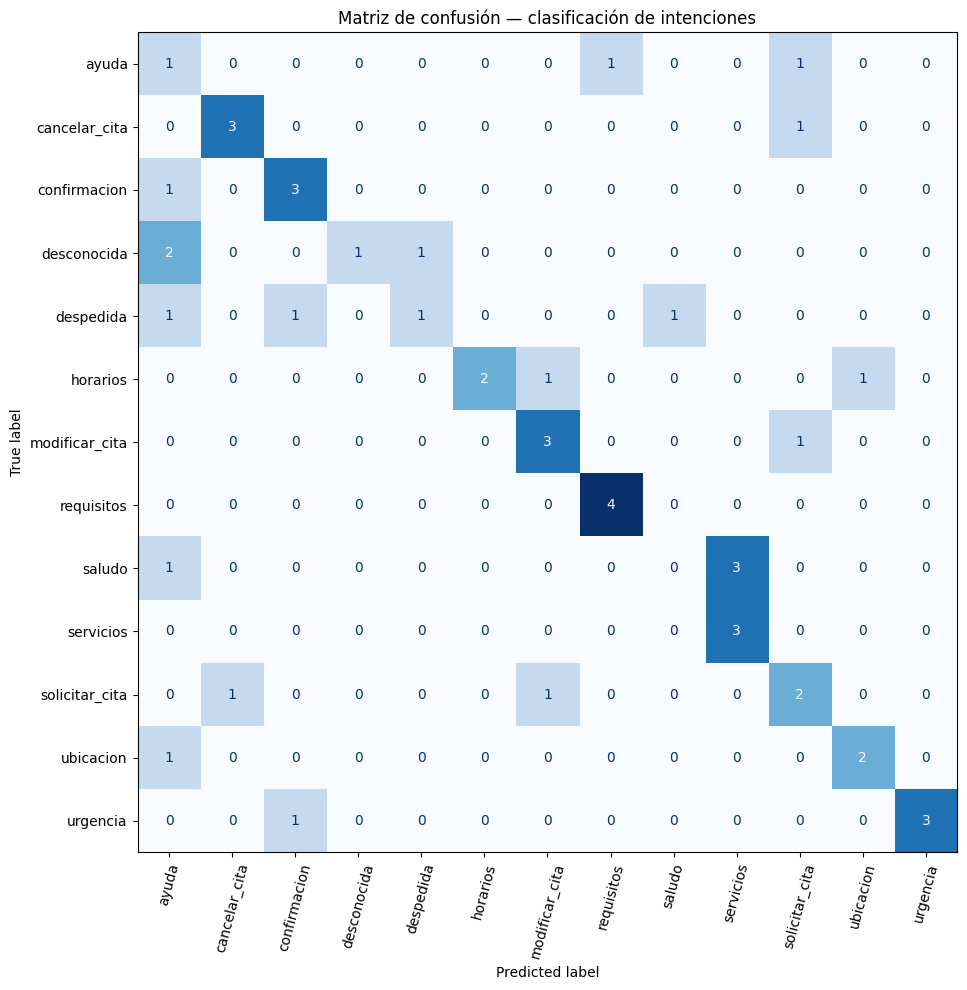

In [6]:
etiquetas = sorted(datos['intencion'].unique())
cm = confusion_matrix(y_test, pred, labels=etiquetas)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=etiquetas)
fig, ax = plt.subplots(figsize=(12,10))
disp.plot(ax=ax, xticks_rotation=75, cmap='Blues', colorbar=False)
plt.title('Matriz de confusión — clasificación de intenciones')
plt.tight_layout()
plt.show()

In [7]:
def clasificar_intencion(mensaje):
    # Regla de seguridad: se priorizan frases de posible urgencia.
    urgente = ['perdi la vision', 'perdida subita', 'quimico', 'dolor ocular intenso',
               'golpe fuerte en el ojo', 'no veo de repente']
    m = normalizar(mensaje)
    if any(frase in m for frase in urgente):
        return 'urgencia', 1.0
    probabilidades = modelo_texto.predict_proba([mensaje])[0]
    idx = int(np.argmax(probabilidades))
    return modelo_texto.classes_[idx], float(probabilidades[idx])

for frase in ['Hola, buenos días', 'Quiero cambiar mi cita',
              '¿Dónde están ubicados?', 'Perdí la visión de repente']:
    print(frase, '=>', clasificar_intencion(frase))

Hola, buenos días => (np.str_('saludo'), 0.5876937455603223)
Quiero cambiar mi cita => (np.str_('modificar_cita'), 0.25338379605554195)
¿Dónde están ubicados? => (np.str_('ubicacion'), 0.3681543647201547)
Perdí la visión de repente => ('urgencia', 1.0)


## 5. Datos de imágenes

Usar imágenes **autorizadas** y etiquetas del conjunto original. Separar entrenamiento, validación y prueba por paciente para evitar filtraciones.

Estructura:

```text
dataset/
  train/clase_1/
  val/clase_1/
  test/clase_1/
```

Repetir las carpetas para cada clase real. No crear etiquetas clínicas manualmente.

## 6. CNN: ResNet50

Se prepara ResNet50 con pesos ImageNet. Primero se congela la base y se entrena la capa de clasificación; después puede ajustarse el modelo. Entrada: 224 × 224 píxeles.

In [10]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications.resnet50 import ResNet50, preprocess_input

RUTA_IMAGENES = '/content/dataset'  # Ajustar a la ruta real
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

if os.path.isdir(RUTA_IMAGENES):
    train_ds = tf.keras.utils.image_dataset_from_directory(
        os.path.join(RUTA_IMAGENES, 'train'), image_size=IMG_SIZE,
        batch_size=BATCH_SIZE, label_mode='int', seed=SEED)
    val_ds = tf.keras.utils.image_dataset_from_directory(
        os.path.join(RUTA_IMAGENES, 'val'), image_size=IMG_SIZE,
        batch_size=BATCH_SIZE, label_mode='int', shuffle=False)
    test_ds = tf.keras.utils.image_dataset_from_directory(
        os.path.join(RUTA_IMAGENES, 'test'), image_size=IMG_SIZE,
        batch_size=BATCH_SIZE, label_mode='int', shuffle=False)

    nombres_clase = train_ds.class_names
    n_clases = len(nombres_clase)
    AUTOTUNE = tf.data.AUTOTUNE

    def preparar(x, y):
        return preprocess_input(tf.cast(x, tf.float32)), y

    train_ds = train_ds.map(preparar).prefetch(AUTOTUNE)
    val_ds = val_ds.map(preparar).prefetch(AUTOTUNE)
    test_ds = test_ds.map(preparar).prefetch(AUTOTUNE)

    base = ResNet50(weights='imagenet', include_top=False,
                    input_shape=(224,224,3))
    base.trainable = False

    entradas = layers.Input(shape=(224,224,3))
    x = base(entradas, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    salidas = layers.Dense(n_clases, activation='softmax')(x)
    modelo_visual = models.Model(entradas, salidas)

    modelo_visual.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    historia = modelo_visual.fit(train_ds, validation_data=val_ds, epochs=8)

    # Ajuste fino opcional: descongelar solo las últimas capas.
    base.trainable = True
    for capa in base.layers[:-30]:
        capa.trainable = False
    modelo_visual.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
        loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    historia_finetune = modelo_visual.fit(
        train_ds, validation_data=val_ds, epochs=5)
else:
    print('No se encontró el dataset de imágenes. Crea la estructura indicada y vuelve a ejecutar esta sección.')

Found 22 files belonging to 2 classes.
Found 4 files belonging to 2 classes.
Found 4 files belonging to 2 classes.
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/8
1/1 ━━━━━━━━━━━━━━━━━━━━ 17s 17s/step - accuracy: 0.5909 - loss: 0.8086 - val_accuracy: 0.7500 - val_loss: 0.7168
Epoch 2/8
1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step - accuracy: 0.6818 - loss: 0.6624 - val_accuracy: 0.5000 - val_loss: 1.0802
Epoch 3/8
1/1 ━━━━━━━━━━━━━━━━━━━━ 12s 12s/step - accuracy: 0.5455 - loss: 1.0196 - val_accuracy: 0.5000 - val_loss: 1.0564
Epoch 4/8
1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step - accuracy: 0.4091 - loss: 1.1172 - val_accuracy: 0.5000 - val_loss: 0.9086
Epoch 5/8
1/1 ━━━━━━━━━━━━━━━━━━━━ 7s 7s/step - accuracy: 0.6818 - loss: 0.5858 - val_accuracy: 0.7500 - val_loss: 0.7527
Epoch 6/8
1/1 ━━━━━━━━━━━━━━━━━━━━ 7s 7s/step - accuracy: 0.6364 - loss: 0.7393 - val_accuracy: 0.5000 - val_loss: 0.6971
Epoch 7/8
1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step - accuracy: 0.6818 - loss: 0.5994 - val_accuracy: 0.

## 7. Evaluación visual

Se calculan accuracy, precision, recall, F1-score y matriz de confusión. Los resultados requieren un dataset real y el entrenamiento completo.

1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
Accuracy:  0.5000
Precision: 0.5000
Recall:    0.5000
F1-score:  0.5000
              precision    recall  f1-score   support

    glaucoma       0.50      0.50      0.50         2
      normal       0.50      0.50      0.50         2

    accuracy                           0.50         4
   macro avg       0.50      0.50      0.50         4
weighted avg       0.50      0.50      0.50         4



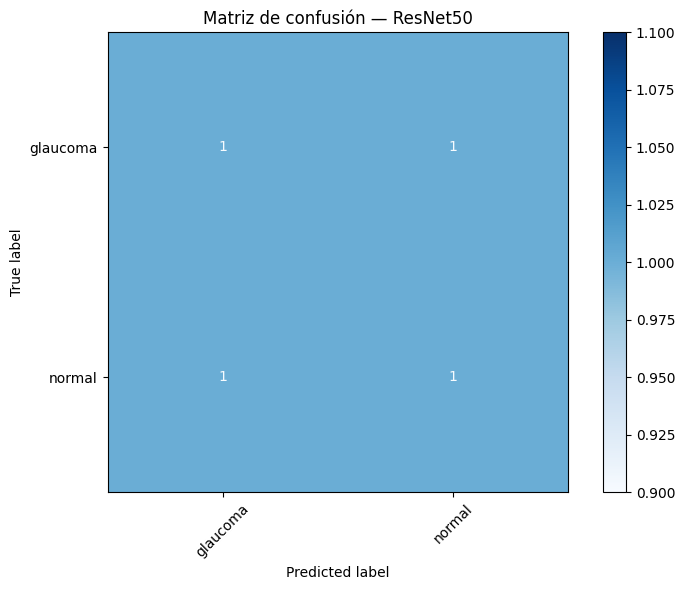

In [11]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix, ConfusionMatrixDisplay

if 'modelo_visual' in globals() and 'test_ds' in globals():
    y_true = np.concatenate([y.numpy() for _, y in test_ds])
    y_prob = modelo_visual.predict(test_ds)
    y_pred = np.argmax(y_prob, axis=1)

    acc = accuracy_score(y_true, y_pred)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average='weighted', zero_division=0)

    print(f'Accuracy:  {acc:.4f}')
    print(f'Precision: {precision:.4f}')
    print(f'Recall:    {recall:.4f}')
    print(f'F1-score:  {f1:.4f}')
    print(classification_report(y_true, y_pred, target_names=nombres_clase, zero_division=0))

    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=nombres_clase)
    fig, ax = plt.subplots(figsize=(8,6))
    disp.plot(ax=ax, xticks_rotation=45, cmap='Blues')
    plt.title('Matriz de confusión — ResNet50')
    plt.tight_layout()
    plt.show()
else:
    print('Evaluación pendiente: falta ejecutar el entrenamiento con imágenes etiquetadas.')

## 8. Integración

El sistema recibe texto o imagen. El chatbot identifica la intención y ResNet50 predice una clase si ya fue entrenada. El resultado es experimental, no un diagnóstico.

In [12]:
def respuesta_chatbot(mensaje):
    intencion, confianza = clasificar_intencion(mensaje)
    respuestas = {
        'saludo': 'Hola. Soy el asistente de la Clínica de Ojos Monterrey. ¿Cómo puedo orientarte?',
        'servicios': 'Puedo compartir información general sobre los servicios oftalmológicos de ejemplo.',
        'horarios': 'El horario de ejemplo es de lunes a viernes de 8:00 a 17:00.',
        'ubicacion': 'La dirección de ejemplo es Av. Chepevera 777, Monterrey.',
        'solicitar_cita': 'Puedo orientarte para solicitar una cita, pero este prototipo no reserva horarios reales.',
        'requisitos': 'Como referencia, considera llevar identificación y estudios previos si los tienes.',
        'modificar_cita': 'Para modificar una cita real debes comunicarte con el personal administrativo.',
        'cancelar_cita': 'Este prototipo no cancela citas reales; contacta al personal administrativo.',
        'urgencia': 'Si presentas pérdida súbita de visión, dolor intenso o una lesión química, busca atención médica urgente.',
        'despedida': 'Gracias por comunicarte. Que tengas buen día.',
        'ayuda': 'Puedo orientar sobre servicios, horarios, ubicación, requisitos y solicitudes de cita.',
        'confirmacion': 'Entendido. Para acciones sobre citas reales se requiere confirmación del personal.',
        'desconocida': 'No identifiqué la solicitud. Puedes preguntar por servicios, horarios, ubicación o citas.'
    }
    return intencion, confianza, respuestas.get(intencion, respuestas['desconocida'])

def clasificar_archivo_imagen(ruta_imagen):
    if 'modelo_visual' not in globals():
        return 'El clasificador visual aún no está entrenado.'
    img = tf.keras.utils.load_img(ruta_imagen, target_size=IMG_SIZE)
    arr = tf.keras.utils.img_to_array(img)
    arr = preprocess_input(np.expand_dims(arr, axis=0))
    prob = modelo_visual.predict(arr, verbose=0)[0]
    idx = int(np.argmax(prob))
    return {
        'clase_predicha': nombres_clase[idx],
        'confianza': float(prob[idx]),
        'aviso': 'Resultado experimental; no constituye diagnóstico médico.'
    }

mensaje = 'Quiero solicitar una cita'
intencion, confianza, respuesta = respuesta_chatbot(mensaje)
print('Intención:', intencion, '| Confianza:', round(confianza,3))
print('Chatbot:', respuesta)

Intención: solicitar_cita | Confianza: 0.3
Chatbot: Puedo orientarte para solicitar una cita, pero este prototipo no reserva horarios reales.


## 9. Resultados y conclusión

**Texto:** El modelo TF-IDF + Naive Bayes permite clasificar las intenciones de los mensajes. Se recomienda ampliar los ejemplos y probar mensajes ambiguos para mejorar los resultados.

**Imagen:** El modelo ResNet50 obtuvo un Accuracy de 50%, Precision de 50%, Recall de 50% y F1-score de 50%. Se evaluaron 4 imágenes, por lo que es necesario ampliar el conjunto de datos y realizar más pruebas.

**Limitaciones:** el conjunto de imágenes es pequeño y los resultados son preliminares. No hay conexión con agenda ni expedientes médicos. Las predicciones no sustituyen la evaluación médica.

**Conclusión:** el proyecto integra clasificación de texto con TF-IDF + Naive Bayes y clasificación de imágenes con ResNet50. Se logró implementar una primera versión, pero es necesario mejorar los datos y realizar más pruebas para aumentar su precisión.

## Referencias

- scikit-learn: https://scikit-learn.org/
- NLTK: https://www.nltk.org/
- Keras / ResNet50: https://keras.io/api/applications/resnet/
- He et al. (2016). *Deep Residual Learning for Image Recognition*.